# Exercise 6 — Bring your own target

*Covers notebooks all. Difficulty: open*

Your science, the ESC, and Jupyter AI as a pair programmer.

In [1]:
import warnings
import numpy as np
import astropy.units as u
import matplotlib.pyplot as plt
import esc_etc
from esc_etc import Simulation, use_lazuli_style

use_lazuli_style()
warnings.filterwarnings("ignore", module="synphot")

def frame_for(sim, max_frame=1000 * u.s):
    """Frame time to use: max_frame, or half the saturation time if that is shorter."""
    return min(u.Quantity(max_frame, u.s), 0.5 * sim.saturation_time())


def hours_to_snr(sim, snr=5, max_frame=1000 * u.s):
    """Integration time (hours) to reach snr with the current configuration; NaN above the speckle plateau."""
    return sim.get_int_time_for_snr(snr, frame_for(sim, max_frame))["int_time_continuous"][0].to_value(u.hr)

This exercise has no solution key beyond a worked example. Work with Jupyter AI as a pair
programmer: you supply the astronomy, it supplies the code, you check the numbers.

### 6.1 — Pick a target

A known planet (the RV giants of exercise 4, a directly imaged companion, a hypothetical Earth
around alpha Cen A), or a disk. Write down: host V magnitude and distance, planet separation or
semi-major axis, and how you get a contrast (albedo and radius, or a measured one).

### 6.2 — Describe it to the agent

A prompt that works: *"I want to image `<planet>` around `<host>` (V = `<mag>`, `<d>` pc) with the
Lazuli ESC. Using esc_etc, build Simulation.from_default with filter R3, hoststar_band 'johnson_v',
the planet's delta magnitude from a contrast of `<C>`, raw contrast 1e-8 and ppgain 30, at a
separation of `<sep>` arcsec. Report the time to S/N 5 with 1000 s frames capped at half the
saturation time, and whether the separation is inside the mask's tabulated range."*

Check what it does against notebooks 03 and 04: does it handle NaN (below the floor)? Does it check
the separation against the table edge before calling `update`?

In [2]:
# Worked example: eps Eri b (V = 3.73, 3.2 pc, a = 3.5 AU -> 1.1", contrast ~4e-9 for 0.5 albedo and 1 R_J).
sim = Simulation.from_default(filter="R3", hoststarmag=3.73, hoststar_band="johnson_v", planetdeltamag=21, contrast=1e-8, ppgain=30, separation=0.4)
cg = sim.coronagraph
edge = cg._lamD.max() * (cg.primary_filter / cg.diameter_primary).to_value(u.arcsec, equivalencies=u.dimensionless_angles())
sep = 3.5 / 3.2
print(f"eps Eri b at {sep:.2f}\" is {'inside' if sep <= edge else 'beyond'} the tabulated dark hole (edge {edge:.2f}\")")
# The ETC cannot model it there. What the planet would need: bring it to the edge and ask.
sim.update(coronagraph__separation=edge * 0.99, scene__planet__deltamag=-2.5 * np.log10(4e-9))
print(f"at the table edge: time to S/N 5 = {hours_to_snr(sim):.1f} h (ppgain 30); plateau {30 * 4e-9 / 1e-8:.1f}")
sim.reset()

eps Eri b at 1.09" is beyond the tabulated dark hole (edge 0.91")
at the table edge: time to S/N 5 = 0.4 h (ppgain 30); plateau 12.0


### 6.3 — One plot, one number

Produce the one plot that answers your question (S/N versus time, time versus contrast, a map, a
sweep over ppgain) and the one number you would put in a proposal.

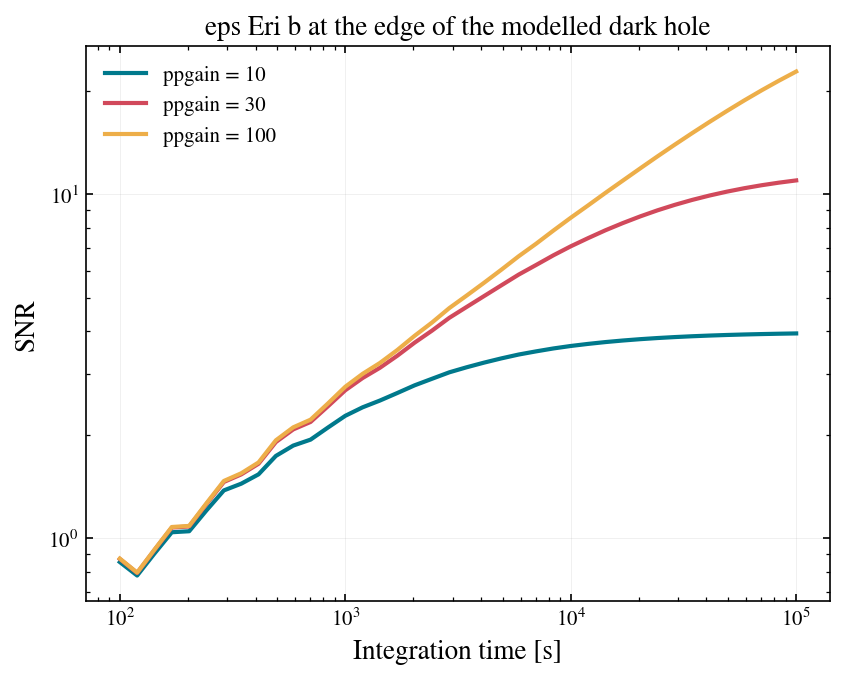

In [3]:
fig, ax = sim.plot_snr_vs_time(sweep={"coronagraph__ppgain": [10, 30, 100]})
ax.set_title("eps Eri b at the edge of the modelled dark hole")
plt.show()

### 6.4 — What was wrong

Ask the agent to list every assumption it made that you did not state (albedo, phase, radius,
flat spectra, EOL throughput, no jitter, the raw contrast being flat across the dark hole). Which
would change the answer by more than a factor of two?

> 🤖 **Ask Jupyter AI:** *List every assumption you made in 6.2 that I did not state, and for each one estimate how much the time to S/N 5 would change if it were wrong.*

***
## Share-back and feedback

Bring back **one plot and one number** to the share-back board, and the observing decision you draw
from them.

> 🤖 **Ask Jupyter AI:** *Draft a GitHub issue for schmidt-observatories/esc-etc describing one thing I
> found missing, confusing or wrong in this exercise, with a minimal code example.*